# ContextNet + MultiNicheNet Workflow

ContextNet and MultiNicheNet can produce communication tables where each path is associated with a condition, group, contrast, or time point. `ccflowR` visualizes those paths as group-colored sender -> ligand -> receptor -> receiver Sankey plots.

This tutorial uses packaged example data to show how condition-aware communication paths can be checked, displayed, filtered, and exported.

### Tutorial Goals

1. Load a MultiNicheNet-style communication table with group information.
2. Confirm the input structure and group counts before plotting.
3. Create group-colored Sankey diagrams.
4. Compare individual conditions using the same visual encoding.
5. Tune highlighting, ordering, and filtering for interpretation.
6. Export interactive and static figures.


### When to Use Multi-Condition Sankey Plots

Use a multi-condition Sankey plot when the same sender -> ligand -> receptor -> receiver schema is available across groups and the analysis question is comparative. Examples include control versus treatment, disease states, developmental stages, spatial zones, or sample groups.

A group-colored ccflowR plot should separate two ideas:

- pathway presence or strength within each condition;
- cell-type abundance or sampling differences, which must be interpreted from the upstream analysis design rather than from the Sankey width alone.


## Data Requirements

### Required Columns
| Column | Type | Description |
|--------|------|-------------|
| `sender` | character | Sending cell type |
| `receiver` | character | Receiving cell type |
| `ligand` | character | Ligand gene symbol |
| `receptor` | character | Receptor gene symbol (optional -- omit with `receptor_col = NULL` for 3-layer plots) |
| `group` | character | Condition label (e.g., "Control", "Treatment") |
| `prioritization_score` | numeric | Path-specific score that directly sets sender -> ligand width |
| `scaled_lfc_receptor` | numeric | Receptor-side differential-expression weight used to redistribute downstream flow |

`read_multinichenet()` maps `prioritization_score` to the activity column used for weighted flow and maps receptor differential expression to the downstream redistribution weight. Ligand differential expression remains optional visualization metadata and does not multiply edge widths.

### Loading Your Own Data

    # Load your MultiNicheNet output file
    data <- read_multinichenet("path/to/multinichenet_output.csv")
    table(data$group)


In [1]:
library(ccflowR)

# Use the full widget + PNG helper for the primary plot. Repeated tutorial
# examples use package-generated static previews to keep committed notebooks
# small enough for public sharing.
display_sankey <- function(p, width = 600, height = 900, static = TRUE, widget = FALSE) {
  if (isTRUE(widget)) {
    sankey_display_notebook(p, width = width, height = height, static = static)
  } else {
    png_file <- tempfile(fileext = ".png")
    ok <- tryCatch({
      sankey_save(p, png_file, width = width, height = height)
      file.exists(png_file) && file.info(png_file)[["size"]] > 0
    }, error = function(e) {
      message("Static preview failed; displaying interactive widget instead: ", conditionMessage(e))
      FALSE
    })
    if (isTRUE(ok) && requireNamespace("IRdisplay", quietly = TRUE)) {
      IRdisplay::display_png(file = png_file)
    } else {
      sankey_display_notebook(p, width = width, height = height, static = FALSE)
    }
  }
  invisible(p)
}


ccflowR v0.1.0 - Cell-Cell Communication Flow Visualization



## Step 1: Load Data


In [2]:
# Use example data for demonstration
ex <- example_multinichenet()
data <- ex$data

# Inspect the data structure
head(data)

# View the groups
table(data$group)


,sender,receiver,ligand,receptor,group,prioritization_score,scaled_lfc_ligand,scaled_lfc_receptor,activity
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,Macrophage,T_cell,TGFB1,TGFBR1,Control,0.45,0.40,0.50,0.45
2,Macrophage,Fibroblast,TNF,TNFRSF1A,Control,0.40,0.35,0.45,0.40
3,T_cell,Macrophage,IFNG,IFNGR1,Control,0.50,0.45,0.55,0.50
4,Fibroblast,Endothelial,VEGFA,KDR,Control,0.42,0.38,0.48,0.42
5,T_cell,B_cell,IL2,IL2RA,Control,0.38,0.32,0.42,0.38
6,Endothelial,Fibroblast,PDGFB,PDGFRB,Control,0.35,0.30,0.40,0.35



  Control   Disease Treatment 
        6        12         9 

In [3]:
# Get a summary of the communication data
summarize_data(data)


$n_interactions
[1] 27

$n_senders
[1] 4

$n_receivers
[1] 5

$n_ligands
[1] 8

$n_receptors
[1] 8

$senders
[1] "Macrophage"  "T_cell"      "Fibroblast"  "Endothelial"

$receivers
[1] "T_cell"      "Fibroblast"  "Macrophage"  "Endothelial" "B_cell"     

$ligands
[1] "TGFB1" "TNF"   "IFNG"  "VEGFA" "IL2"   "PDGFB" "IL6"   "CCL2" 

$receptors
[1] "TGFBR1"   "TNFRSF1A" "IFNGR1"   "KDR"      "IL2RA"    "PDGFRB"   "IL6R"    
[8] "CCR2"

The packaged example contains 27 interactions across three simulated conditions with different network densities: Control has 6 core interactions, Treatment has 9, and Disease has 12. The added paths illustrate how a condition-associated network can contain additional inflammatory or immune-activation hypotheses; they are not evidence for a real disease system. Each row carries a path-specific `prioritization_score`, so MultiNicheNet rows remain independent activity units by default. `scaled_lfc_receptor` redistributes flow downstream, whereas `scaled_lfc_ligand` is optional visualization metadata.


## Step 2: Define Colors

**Why two color sets?** MultiNicheNet analysis requires two separate color mappings. Cell type colors identify senders and receivers. Group colors map to experimental conditions so flows can be colored by condition, making it possible to see at a glance which pathways are active in which condition.


In [4]:
# Cell type colors (from example data)
celltype_colors <- ex$colors
print(celltype_colors)

# Group/condition colors (from example data)
group_colors <- ex$group_colors
print(group_colors)

# Verify all groups have colors
groups_in_data <- unique(data$group)
missing <- setdiff(groups_in_data, names(group_colors))
if (length(missing) > 0) {
  cat("Warning: No colors defined for:", paste(missing, collapse = ", "), "\n")
} else {
  cat("All groups have colors assigned\n")
}


 Macrophage      T_cell  Fibroblast Endothelial      B_cell 
  "#E41A1C"   "#377EB8"   "#4DAF4A"   "#984EA3"   "#FF7F00" 


  Control Treatment   Disease 
"#66C2A5" "#FC8D62" "#8DA0CB" 


All groups have colors assigned


## Step 3: Create a Group-Colored Sankey

**Why color by group?** This is the defining feature of MultiNicheNet visualization. Coloring flows by condition lets you see which signaling pathways are shared across conditions and which are condition-specific.

Two functions work together: `sankey_colors(by = "condition")` tells ccflowR to color flows by condition, and `sankey_group_colors()` provides the color mapping.


<!doctype html>
 
 
 
 




<link href="data:text/css;charset-utf-8;base64,LmNvbnRhaW5lci1mbHVpZC5jcm9zc3RhbGstYnNjb2xze21hcmdpbi1sZWZ0Oi0zMHB4O21hcmdpbi1yaWdodDotMzBweDt3aGl0ZS1zcGFjZTpub3JtYWx9Ym9keT4uY29udGFpbmVyLWZsdWlkLmNyb3NzdGFsay1ic2NvbHN7bWFyZ2luLWxlZnQ6YXV0bzttYXJnaW4tcmlnaHQ6YXV0b30uY3Jvc3N0YWxrLWlucHV0LWNoZWNrYm94Z3JvdXAgLmNyb3NzdGFsay1vcHRpb25zLWdyb3VwIC5jcm9zc3RhbGstb3B0aW9ucy1jb2x1bW57ZGlzcGxheTppbmxpbmUtYmxvY2s7cGFkZGluZy1yaWdodDoxMnB4O3ZlcnRpY2FsLWFsaWduOnRvcH1AbWVkaWEgb25seSBzY3JlZW4gYW5kIChtYXgtd2lkdGg6IDQ4MHB4KXsuY3Jvc3N0YWxrLWlucHV0LWNoZWNrYm94Z3JvdXAgLmNyb3NzdGFsay1vcHRpb25zLWdyb3VwIC5jcm9zc3RhbGstb3B0aW9ucy1jb2x1bW57ZGlzcGxheTpibG9jaztwYWRkaW5nLXJpZ2h0OmluaGVyaXR9fS5jcm9zc3RhbGstaW5wdXR7bWFyZ2luLWJvdHRvbToxNXB4fS5jcm9zc3RhbGstaW5wdXQgLmNvbnRyb2wtbGFiZWx7bWFyZ2luLWJvdHRvbTowO3ZlcnRpY2FsLWFsaWduOm1pZGRsZX0uY3Jvc3N0YWxrLWlucHV0IGlucHV0W3R5cGU9ImNoZWNrYm94Il17bWFyZ2luOjRweCAwIDA7bWFyZ2luLXRvcDoxcHg7bGluZS1oZWlnaHQ6bm9ybWFsfS5jcm9zc3RhbGstaW5wdXQgLmNoZWNrYm94e3Bvc2l0aW9uOnJlbGF0aXZlO2Rpc3BsYXk6YmxvY2s7bWFyZ2luLXRvcDoxMHB4O21hcmdpbi1ib3R0b206MTBweH0uY3Jvc3N0YWxrLWlucHV0IC5jaGVja2JveD5sYWJlbHtwYWRkaW5nLWxlZnQ6MjBweDttYXJnaW4tYm90dG9tOjA7Zm9udC13ZWlnaHQ6NDAwO2N1cnNvcjpwb2ludGVyfS5jcm9zc3RhbGstaW5wdXQgLmNoZWNrYm94IGlucHV0W3R5cGU9ImNoZWNrYm94Il0sLmNyb3NzdGFsay1pbnB1dCAuY2hlY2tib3gtaW5saW5lIGlucHV0W3R5cGU9ImNoZWNrYm94Il17cG9zaXRpb246YWJzb2x1dGU7bWFyZ2luLXRvcDoycHg7bWFyZ2luLWxlZnQ6LTIwcHh9LmNyb3NzdGFsay1pbnB1dCAuY2hlY2tib3grLmNoZWNrYm94e21hcmdpbi10b3A6LTVweH0uY3Jvc3N0YWxrLWlucHV0IC5jaGVja2JveC1pbmxpbmV7cG9zaXRpb246cmVsYXRpdmU7ZGlzcGxheTppbmxpbmUtYmxvY2s7cGFkZGluZy1sZWZ0OjIwcHg7bWFyZ2luLWJvdHRvbTowO2ZvbnQtd2VpZ2h0OjQwMDt2ZXJ0aWNhbC1hbGlnbjptaWRkbGU7Y3Vyc29yOnBvaW50ZXJ9LmNyb3NzdGFsay1pbnB1dCAuY2hlY2tib3gtaW5saW5lKy5jaGVja2JveC1pbmxpbmV7bWFyZ2luLXRvcDowO21hcmdpbi1sZWZ0OjEwcHh9Cg==" rel="stylesheet" />

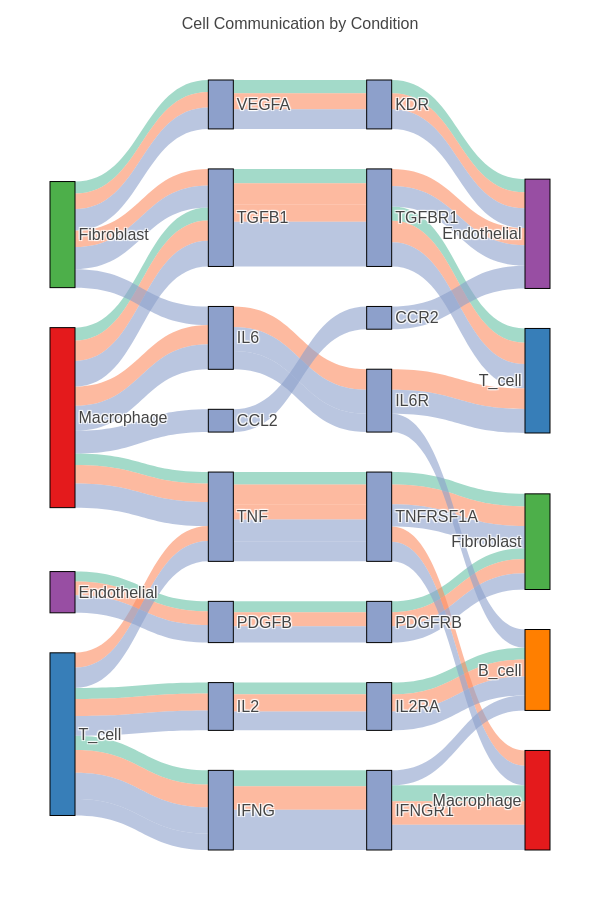

In [5]:
p <- sankey_plot(data, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_alpha(0.6) +
  sankey_title("Cell Communication by Condition")
display_sankey(p, widget = TRUE)


**Reading the plot:**
- Each flow is colored by its experimental condition
- Where flows for the same interaction overlap, you can see which conditions share that pathway
- Sender -> ligand thickness reflects the path-specific prioritization score for each condition; downstream widths conserve that flow while dividing it by receptor-side weights
- Ligand-receptor pairs present in all three conditions appear as stacked colored flows at the same position


## Step 4: Compare Individual Conditions

The combined group-colored plot shows all conditions at once but can become dense. Per-condition plots provide cleaner views for direct side-by-side comparison. A complete order supplied through `sankey_order()` remains exact across panels. A partial order preserves only the named relative constraints and allows the remaining nodes to adapt to each condition's topology.


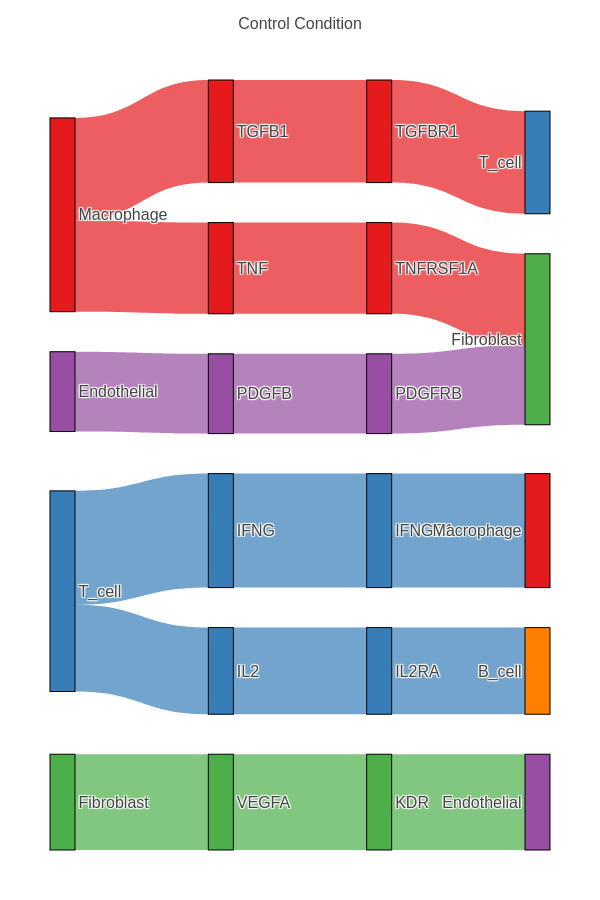

In [6]:
# Filter to Control only
control_data <- data[data$group == "Control", ]

p <- sankey_plot(control_data, celltype_colors) +
  sankey_colors(by = "sender") +
  sankey_alpha(0.7) +
  sankey_title("Control Condition")
display_sankey(p)


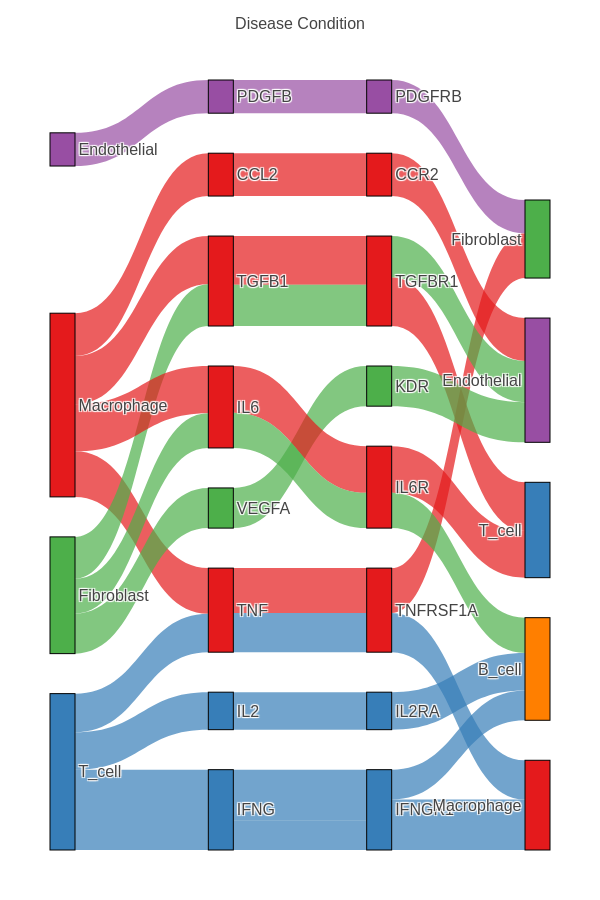

In [7]:
# Filter to Disease only
disease_data <- data[data$group == "Disease", ]

p <- sankey_plot(disease_data, celltype_colors) +
  sankey_colors(by = "sender") +
  sankey_alpha(0.7) +
  sankey_title("Disease Condition")
display_sankey(p)


Compare the two plots: Control has only 6 interactions, while Disease adds inflammatory pathways (CCL2, expanded IFNG/IL6 signaling to B_cell). Macrophage sends 2 signals in Control but 4 in Disease, and shared pathways like TGFB1 show progressively stronger signals.


## Step 5: Customize Your Figure

ccflowR customizations work the same way with multi-condition data. See the **Parameter Reference Guide** for all options.

**New features:**
- `sankey_colors(by = "steelblue")` -- use any color string for monochrome flows
- `sankey_nodes(arrangement = "snap")` -- allow Plotly to snap or drag nodes when explicit custom positions are not required
- `sankey_plot(..., receptor_col = NULL)` -- omit receptor layer for 3-layer diagrams


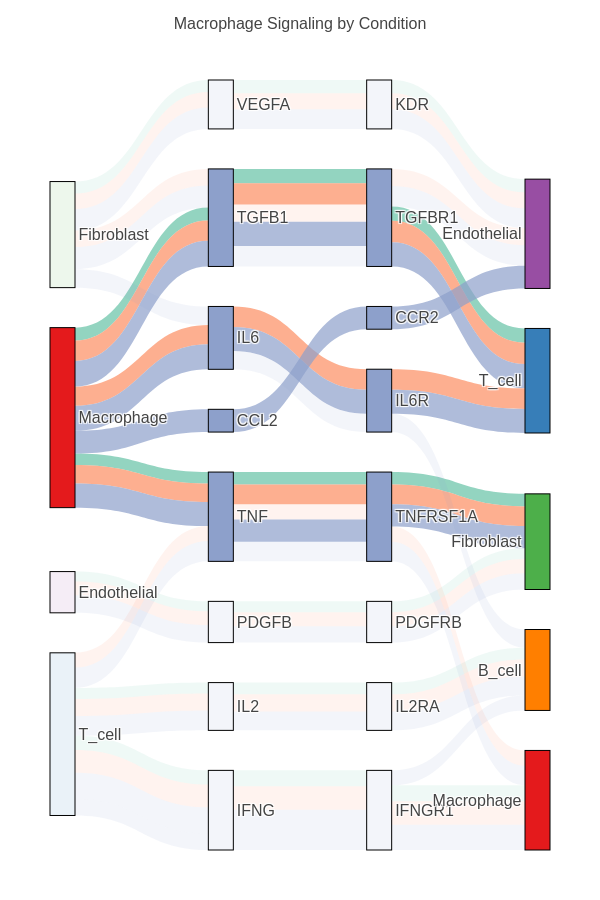

In [8]:
# Highlight Macrophage signaling across all conditions
p <- sankey_plot(data, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_highlight(senders = "Macrophage", dim_alpha = 0.1) +
  sankey_alpha(0.7) +
  sankey_title("Macrophage Signaling by Condition")
display_sankey(p)


### Custom Node Ordering

Without `sankey_order()`, Plotly controls node placement. After a custom sequence is supplied, ccflowR preserves the relative order of the named nodes and deterministically optimizes the remaining layout freedom to reduce activity-weighted crossings. Supply complete layer orders when exact cross-panel positions are required. Use `mode = "fixed"` only for the historical exact-leading-order behavior.


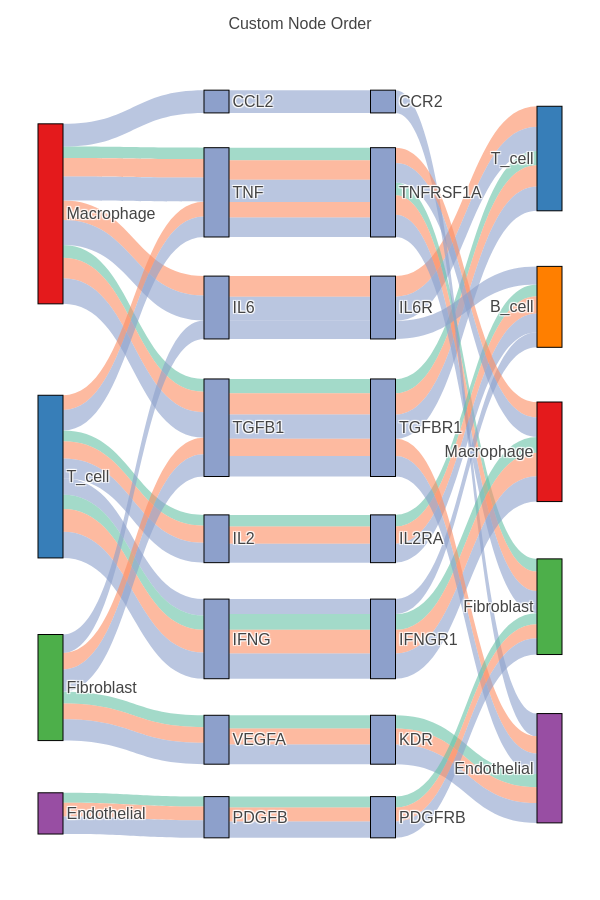

In [9]:
p <- sankey_plot(data, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_order(
    senders = c("Macrophage", "T_cell", "B_cell", "Fibroblast", "Endothelial"),
    receivers = c("T_cell", "B_cell", "Macrophage", "Fibroblast", "Endothelial")
  ) +
  sankey_alpha(0.6) +
  sankey_title("Custom Node Order")
display_sankey(p)


## Step 6: Filter Top Interactions

MultiNicheNet data often contains many interactions. Use `filter_top_pathways()` with `per_group = TRUE` to get the top N from each condition, ensuring balanced representation across groups.


Interactions per group after filtering:



  Control   Disease Treatment 
        5         5         5 


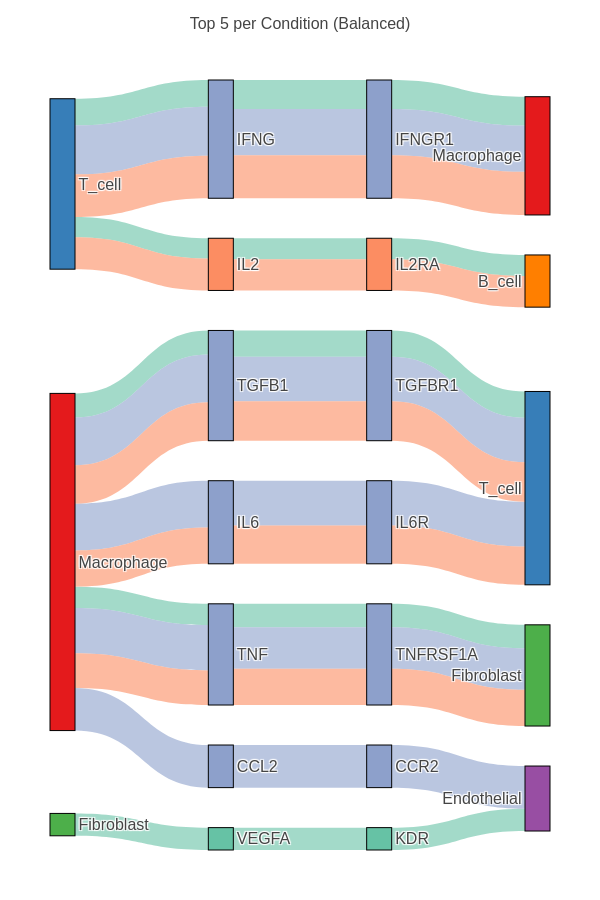

In [10]:
# Filter to top 5 per condition — ensures balanced representation
top_per_group <- filter_top_pathways(data, n = 5, per_group = TRUE, group_col = "group")
cat("Interactions per group after filtering:\n")
print(table(top_per_group$group))

p <- sankey_plot(top_per_group, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_alpha(0.6) +
  sankey_title("Top 5 per Condition (Balanced)")
display_sankey(p)


## Step 7: Export

Save your figure as HTML (interactive) or static formats (PNG, PDF, SVG). See the **Parameter Reference Guide** for all export options and format details.


In [11]:
# Build a publication-ready figure
p <- sankey_plot(data, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_highlight(senders = "Macrophage") +
  sankey_alpha(0.6) +
  sankey_title("Macrophage Signaling by Condition")

html_file <- tempfile(fileext = ".html")
html_ok <- tryCatch({
  sankey_save(p, html_file)
  file.exists(html_file) && file.info(html_file)[["size"]] > 0
}, error = function(e) {
  message("HTML export skipped in this run: ", conditionMessage(e))
  FALSE
})
cat("HTML export check:", if (html_ok) "ok" else "skipped", "\n")

png_file <- tempfile(fileext = ".png")
png_ok <- tryCatch({
  sankey_save(p, png_file, width = 700, height = 900)
  file.exists(png_file) && file.info(png_file)[["size"]] > 0
}, error = function(e) {
  message("PNG export skipped in this run: ", conditionMessage(e))
  FALSE
})
cat("PNG export check:", if (png_ok) "ok" else "skipped", "\n")


HTML export check: ok 


PNG export check: ok 


## Complete Workflow

    library(ccflowR)

    # 1. Load your MultiNicheNet output
    data <- read_multinichenet("path/to/multinichenet_output.csv")
    print(table(data$group))

    # 2. Define colors
    celltype_colors <- c(
      "B Cell" = "#17BECF", "T Cell" = "#006837",
      "Myeloid" = "#FF7F0E", "Fibroblast" = "#9C46D3",
      "Epithelial" = "#1F77B4", "Endothelial" = "#E89FBD"
    )
    group_colors <- c(
      "Control" = "#ADD8E6", "Treatment" = "#F08080", "Disease" = "#90EE90"
    )

    # 3. Create comparison figure
    p <- sankey_plot(data, celltype_colors, group_col = "group") +
      sankey_colors(by = "condition") +
      sankey_group_colors(group_colors) +
      sankey_alpha(0.6) +
      sankey_title("Condition Comparison")

    # 4. Save (see Parameter Reference Guide for all export options)
    sankey_save(p, "Figure2_comparison.html")
    sankey_save(p, "Figure2_comparison.png", width = 700, height = 900)


## Troubleshooting

| Issue | Solution |
|-------|----------|
| "group column not found" | Ensure your data has a `group` column, or specify the correct name with `group_col` |
| Colors don't match conditions | Check that `sankey_group_colors()` names match unique values in the group column |
| Too many flows | Use `filter_top_pathways(data, n = 10, per_group = TRUE)` to reduce density |
| Named nodes appear with unlisted nodes between them | Constrained mode preserves relative order while optimizing the remaining nodes. Supply a complete order, or use `mode = "fixed"` for historical exact-leading positions |
| Want receptor-free view | Use `sankey_plot(..., receptor_col = NULL)` for a 3-layer Sender -> Ligand -> Receiver diagram |


## Next Steps
- **Single condition analysis**: See the [NicheNet tutorial](tutorial-contextnet-nichenet.ipynb) for detailed single-condition workflows
- **Parameter reference**: See the [Parameter Guide](tutorial-parameter-guide.ipynb) for all customization options, including 3-layer mode (`receptor_col`), fixed flow colors, and node arrangement modes
- **Export options**: `sankey_save()` supports HTML, PNG, PDF, and SVG formats
